# 順序尺度の評価（QWK・Strict/Lenient・分類 vs 回帰）

書籍 第2章「分類・回帰問題の解き方」（2-3 文章の品質推定：2-3-3 評価、練習問題 4）に対応する演習ノートブックです。
CPU のみ・数秒で実行でき、1〜6 や 1〜5 のような順序付きスコアを予測・評価するときのポイントを体験します。

1. **書籍 表 2.1（6 段階評価の混同行列）の再現とヒートマップ可視化**
2. **Strict 正解率 / Lenient 正解率（±1 許容）と重みつきカッパ係数（QWK）の実装・検証**
3. **分類 vs 回帰 vs ランキングと MSE 最小化の罠**（`phrase-annotation.csv` の 5 段階評価を使用）

In [1]:
!curl -fLO https://raw.githubusercontent.com/mamorlis/nlpbook/refs/heads/main/misc/phrase-annotation.csv

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import cohen_kappa_score, mean_absolute_error, mean_squared_error
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.pipeline import make_pipeline

---

## 1. 書籍 表 2.1（6 段階ライティング評価）の混同行列と可視化（2-3-3）

書籍 表 2.1（p.72）に示されている 1〜6 の 6 段階評価の混同行列をそのまま再現し、スコアごとの誤差の傾向をヒートマップで確認します。

,予測1,予測2,予測3,予測4,予測5,予測6
正解1,0,3,7,1,0,0
正解2,0,32,56,9,1,0
正解3,0,21,176,121,9,0
正解4,0,0,55,202,47,0
正解5,0,0,6,56,60,0
正解6,0,0,0,3,11,0


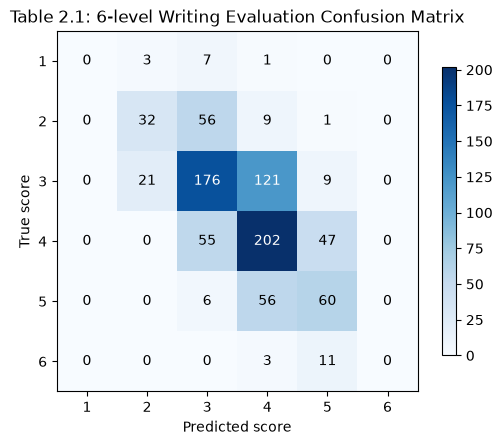

In [3]:
# 書籍 表 2.1 の混同行列（行: 正解 1〜6、列: 予測 1〜6）
cm_table21 = np.array([
    [0,  3,   7,   1,  0, 0],
    [0, 32,  56,   9,  1, 0],
    [0, 21, 176, 121,  9, 0],
    [0,  0,  55, 202, 47, 0],
    [0,  0,   6,  56, 60, 0],
    [0,  0,   0,   3, 11, 0],
])
scores = [1, 2, 3, 4, 5, 6]
display(pd.DataFrame(cm_table21, index=[f"正解{s}" for s in scores], columns=[f"予測{s}" for s in scores]))

fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(cm_table21, cmap="Blues")
ax.set_xticks(range(6), labels=scores)
ax.set_yticks(range(6), labels=scores)
ax.set_xlabel("Predicted score")
ax.set_ylabel("True score")
ax.set_title("Table 2.1: 6-level Writing Evaluation Confusion Matrix")
for i in range(6):
    for j in range(6):
        val = cm_table21[i, j]
        ax.text(j, i, str(val), ha="center", va="center",
                color="white" if val > cm_table21.max() * 0.5 else "black")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

---

## 2. Strict / Lenient 評価と重みつきカッパ係数（QWK）の定義式実装

多クラス分類として評価する際、完全一致だけを正解とする **Strict 評価** と、隣接 ±1 までを許容する **Lenient 評価** に加え、外れ幅の二乗でペナルティを与える **重みつきカッパ係数（Quadratic Weighted Kappa; QWK）** がよく使われます。

$$\kappa = 1 - \frac{\sum_{i=1}^{k}\sum_{j=1}^{k} w_{ij} O_{ij}}{\sum_{i=1}^{k}\sum_{j=1}^{k} w_{ij} E_{ij}}, \quad w_{ij} = \frac{(i - j)^2}{(k - 1)^2}$$

（※ 書籍 p.73 の[正誤表](../errata.md) に従って右辺に $1 -$ を付けた式を実装し、`scikit-learn` の `cohen_kappa_score(..., weights="quadratic")` と一致することを確認します。）

In [4]:
def compute_qwk_from_cm(cm):
    k = cm.shape[0]
    n = cm.sum()
    O = cm / n
    hist_true = cm.sum(axis=1) / n
    hist_pred = cm.sum(axis=0) / n
    E = np.outer(hist_true, hist_pred)

    idx = np.arange(k)
    W = ((idx[:, None] - idx[None, :]) ** 2) / ((k - 1) ** 2)
    return float(1.0 - np.sum(W * O) / np.sum(W * E))

# Strict 正解率・Lenient 正解率 (±1)・QWK を計算
total = cm_table21.sum()
strict_acc = np.trace(cm_table21) / total
lenient_acc = sum(
    cm_table21[i, j]
    for i in range(6) for j in range(6)
    if abs(i - j) <= 1
) / total

# 混同行列から元データ列を復元して sklearn でも検証
y_true_21, y_pred_21 = [], []
for i in range(6):
    for j in range(6):
        cnt = cm_table21[i, j]
        y_true_21.extend([i + 1] * cnt)
        y_pred_21.extend([j + 1] * cnt)

qwk_scratch = compute_qwk_from_cm(cm_table21)
qwk_sklearn = cohen_kappa_score(y_true_21, y_pred_21, weights="quadratic")

print(f"総件数: {total} 件")
print(f"Strict 正解率 (完全一致) : {strict_acc:.4f}")
print(f"Lenient 正解率 (±1 許容) : {lenient_acc:.4f}")
print(f"QWK (定義式実装)         : {qwk_scratch:.4f}")
print(f"QWK (scikit-learn)       : {qwk_sklearn:.4f}")

総件数: 876 件
Strict 正解率 (完全一致) : 0.5365
Lenient 正解率 (±1 許容) : 0.9589
QWK (定義式実装)         : 0.6216
QWK (scikit-learn)       : 0.6216


表 2.1 では完全一致（Strict）は約 53.7% に見えますが、±1 以内（Lenient）で見ると約 95.9% に達し、QWK も `0.622` となっていて、大きな外しが少ないことがわかります。

---

## 3. 分類モデル vs 回帰モデルと MSE の罠（`phrase-annotation.csv`）

書籍 2-3-3（p.73）では、1〜5 のようなスコアを**回帰（MSE 最小化）**で予測すると、データ全体の誤差を小さくするために**平均値（3 周辺）ばかりを出力してしまう**問題が指摘されています。
第5章のサンプルデータ `phrase-annotation.csv`（`極性` 列が 1〜5 の 5 段階、しかも 1・3・5 に集中している）を使って、**分類モデル（ロジスティック回帰）**と**回帰モデル（Ridge 回帰）**を比較してみましょう。

In [5]:
df = pd.read_csv("phrase-annotation.csv")
print("5段階『極性』の分布:", df["極性"].value_counts().sort_index().to_dict())

cv = KFold(n_splits=5, shuffle=True, random_state=42)

# A) 多クラス分類モデルとして学習
clf = make_pipeline(TfidfVectorizer(analyzer="char_wb", ngram_range=(1, 3)), LogisticRegression(max_iter=1000, C=3.0))
pred_cls = cross_val_predict(clf, df["フレーズ"], df["極性"], cv=cv)

# B) 回帰モデル（二乗誤差最小化）として学習し、四捨五入して 1〜5 に丸める
reg = make_pipeline(TfidfVectorizer(analyzer="char_wb", ngram_range=(1, 3)), Ridge(alpha=1.0))
pred_reg_cont = cross_val_predict(reg, df["フレーズ"], df["極性"], cv=cv)
pred_reg_round = np.clip(np.rint(pred_reg_cont), 1, 5).astype(int)

# C) 常に中央のカテゴリ 3 を返すダミー予測
pred_mean = np.full(len(df), 3)

rows = []
for name, p_cont, p_disc in [
    ("多クラス分類 (LogisticRegression)", pred_cls, pred_cls),
    ("回帰 (Ridge + 四捨五入)", pred_reg_cont, pred_reg_round),
    ("常に中央のカテゴリ 3 を出力", pred_mean, pred_mean),
]:
    rows.append({
        "手法": name,
        "Strict正解率": round(float(np.mean(p_disc == df["極性"])), 3),
        "MSE": round(mean_squared_error(df["極性"], p_cont), 3),
        "MAE": round(mean_absolute_error(df["極性"], p_cont), 3),
        "QWK": round(cohen_kappa_score(df["極性"], p_disc, weights="quadratic"), 3),
        "予測スコアの標準偏差": round(float(np.std(p_disc)), 3),
    })

display(pd.DataFrame(rows))
print("予測スコアの分布:")
print("  分類モデル:", pd.Series(pred_cls).value_counts().sort_index().to_dict())
print("  回帰モデル:", pd.Series(pred_reg_round).value_counts().sort_index().to_dict())

5段階『極性』の分布: {1: 18, 2: 12, 3: 32, 4: 10, 5: 28}


,手法,Strict正解率,MSE,MAE,QWK,予測スコアの標準偏差
0,多クラス分類 (LogisticRegression),0.51,3.090,1.110,0.291,1.226
1,回帰 (Ridge + 四捨五入),0.30,1.719,1.094,0.143,0.375
2,常に中央のカテゴリ 3 を出力,0.32,2.060,1.140,0.000,0.000


予測スコアの分布:
  分類モデル: {1: 6, 2: 1, 3: 32, 5: 61}
  回帰モデル: {2: 1, 3: 84, 4: 15}


- **常に 3 を出すモデル**や**回帰モデル**は、MSE や MAE だけ見ると悪くないように見えますが、予測が中央（2〜4）に集まりすぎてしまい、**QWK（重みつきカッパ係数）は大きく下がります**（書籍 p.73）。
- 順序尺度タスクでは MSE / MAE だけでなく、**混同行列と QWK（または順位相関係数）** をあわせて確認することが重要です。

---

## 4. 訓練データだけで5段階の境界を決める

前節の Ridge 回帰では、連続値の予測を四捨五入して1〜5に戻しました。ここでは同じ Ridge 回帰を使い、5段階に区切る4つの境界を訓練データから決めます。

1. 各分割の訓練データをさらに4分割し、各事例について、その事例を学習に使っていないモデルで予測値を得ます。
2. 訓練データで「1以下」「2以下」「3以下」「4以下」のラベルが占める割合を求めます。例えば「2以下」が30%なら、手順1で得た予測値の30パーセンタイルを2と3の境界にします。
3. 訓練データ全体で Ridge を学習し、決めた境界を使ってテスト側の予測値を1〜5に変換します。

前節と同じ5分割を使い、QWK と完全一致率（Strict 正解率）を比較します。テスト側の正解ラベルは、最後の評価にだけ使います。

In [6]:
from sklearn.base import clone

texts = df["フレーズ"].to_numpy()
ratings = df["極性"].to_numpy()
pred_reg_calibrated = np.empty_like(ratings)
inner_cv = KFold(n_splits=4, shuffle=True, random_state=42)

for train_idx, test_idx in cv.split(texts):
    train_texts, train_ratings = texts[train_idx], ratings[train_idx]
    train_predictions = cross_val_predict(reg, train_texts, train_ratings, cv=inner_cv)
    cumulative_fractions = [(train_ratings <= level).mean() for level in range(1, 5)]
    boundaries = np.quantile(train_predictions, cumulative_fractions)

    model = clone(reg).fit(train_texts, train_ratings)
    test_predictions = model.predict(texts[test_idx])
    pred_reg_calibrated[test_idx] = np.searchsorted(boundaries, test_predictions, side="right") + 1

comparison = [
    ("多クラス分類 (LogisticRegression)", pred_cls),
    ("回帰 (Ridge + 四捨五入)", pred_reg_round),
    ("常に中央のカテゴリ 3 を出力", pred_mean),
    ("回帰 (Ridge + 訓練データで決めた境界)", pred_reg_calibrated),
]
pd.DataFrame([
    {
        "手法": name,
        "QWK": cohen_kappa_score(ratings, predictions, weights="quadratic"),
        "Strict正解率": np.mean(predictions == ratings),
    }
    for name, predictions in comparison
]).round(3)

,手法,QWK,Strict正解率
0,多クラス分類 (LogisticRegression),0.291,0.51
1,回帰 (Ridge + 四捨五入),0.143,0.30
2,常に中央のカテゴリ 3 を出力,0.000,0.32
3,回帰 (Ridge + 訓練データで決めた境界),0.477,0.33


このサンプルでは、訓練データから境界を決めた Ridge は、四捨五入した Ridge より QWK が高くなりました。一方、完全一致率では多クラス分類が最も高くなりました。予測が完全に一致したかを重視する場合と、外れ幅も考慮する場合で、選ぶ手法が変わります。